# Debugging augments and speed

The goal of this notebook is to ttry to understand why I'm seeing such a decrease in performance when doing augments differently using keras3 layers vs just standard tf ops. Is it a parallelization thing? Is it even slower or am I imagining it? Let's get to the bottom of it with a simple example.

To start with I'm thinking of using the tutorial from the kerascv website.
https://keras.io/guides/keras_cv/classification_with_keras_cv/#train-a-classifier-from-scratch
I'll just do a simple implementation with no augments, then add augments one by one and test performance.

In [119]:
import datetime
from pathlib import Path

import tensorflow as tf
import tensorflow_datasets as tfds
import keras
import keras_cv
from tensorflow.data import AUTOTUNE
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
NUM_CLASSES = 101
EPOCHS = 10
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

### no augments

In [100]:
train_ds, eval_ds = tfds.load(
    "caltech101",
    split=["train", "test"],
    as_supervised="true"
)

resizing = keras_cv.layers.Resizing(
    IMAGE_SIZE[0], IMAGE_SIZE[1], crop_to_aspect_ratio=True    
)

def preprocess_inputs(image, label):
    image = tf.cast(image, tf.float32)
    image = image / 255.
    return resizing(image), tf.one_hot(label, NUM_CLASSES)

train_ds = train_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)
eval_ds = eval_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)

train_ds = train_ds.batch(BATCH_SIZE)
eval_ds = eval_ds.batch(BATCH_SIZE)

In [101]:
next(iter(train_ds.take(1)))[0].numpy().max()

2024-09-04 10:54:09.480048: W tensorflow/core/kernels/data/cache_dataset_ops.cc:913] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


1.0

In [102]:
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(
    "efficientnetv2_b0_imagenet"
)
model = keras_cv.models.ImageClassifier(
    backbone=backbone,
    num_classes=NUM_CLASSES,
    activation="softmax",
)
model.compile(
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    metrics=["accuracy"]
)

In [103]:
starttime = datetime.datetime.today()
endtime = datetime.datetime.today()

print(endtime - starttime)

0:00:00.000018


In [104]:
starttime = datetime.datetime.today()
history = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=EPOCHS,
)
endtime = datetime.datetime.today()

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 74s 322ms/step - accuracy: 0.0114 - loss: 4.5699 - val_accuracy: 0.0120 - val_loss: 4.5950
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.0247 - loss: 4.5271 - val_accuracy: 0.0251 - val_loss: 4.5486
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.0435 - loss: 4.4838 - val_accuracy: 0.0511 - val_loss: 4.4954
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.0742 - loss: 4.4362 - val_accuracy: 0.0917 - val_loss: 4.4371
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.1089 - loss: 4.3862 - val_accuracy: 0.1412 - val_loss: 4.3686
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.1573 - loss: 4.3312 - val_accuracy: 0.1917 - val_loss: 4.2896
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.1993 - loss: 4.2739 - val_accuracy: 0.2498 - val_loss: 4.2042
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.2619 - loss: 4.2091 - val_accuracy: 0.3095 -

In [106]:
endtime - starttime

datetime.timedelta(seconds=114, microseconds=759156)

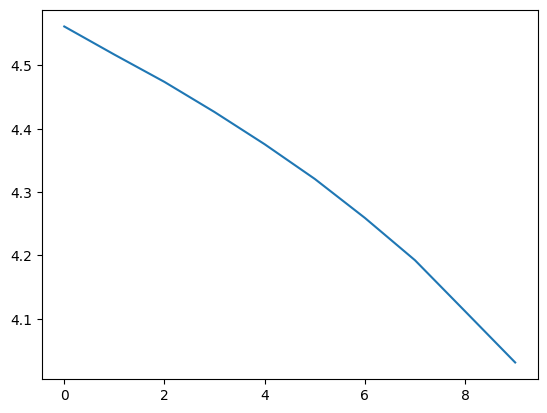

In [107]:
plt.plot(
    history.history["loss"]
)

### let's try with a randomflip

In [27]:
train_ds, eval_ds = tfds.load(
    "caltech101",
    split=["train", "test"],
    as_supervised="true"
)

resizing = keras_cv.layers.Resizing(
    IMAGE_SIZE[0], IMAGE_SIZE[1], crop_to_aspect_ratio=True    
)

randomflip = keras_cv.layers.RandomFlip()

def preprocess_inputs(image, label):
    image = tf.cast(image, tf.float32)
    image = image / 255.
    return resizing(image), tf.one_hot(label, NUM_CLASSES)

train_ds = train_ds.map(lambda x, y: (randomflip(x), y), num_parallel_calls=AUTOTUNE)
train_ds = train_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)

eval_ds = eval_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
eval_ds = eval_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [28]:
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(
    "efficientnetv2_b0_imagenet"
)
model = keras_cv.models.ImageClassifier(
    backbone=backbone,
    num_classes=NUM_CLASSES,
    activation="softmax",
)
model.compile(
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    metrics=["accuracy"]
)

In [29]:
starttime = datetime.datetime.today()
history = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=EPOCHS,
)
endtime = datetime.datetime.today()

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 70s 340ms/step - accuracy: 0.0117 - loss: 4.5713 - val_accuracy: 0.0128 - val_loss: 4.5668
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.0181 - loss: 4.5307 - val_accuracy: 0.0293 - val_loss: 4.5147
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.0404 - loss: 4.4844 - val_accuracy: 0.0649 - val_loss: 4.4601
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.0686 - loss: 4.4393 - val_accuracy: 0.1029 - val_loss: 4.4040
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.1004 - loss: 4.3848 - val_accuracy: 0.1463 - val_loss: 4.3395
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.1566 - loss: 4.3304 - val_accuracy: 0.1869 - val_loss: 4.2652
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.2068 - loss: 4.2696 - val_accuracy: 0.2390 - val_loss: 4.1858
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.2702 - loss: 4.2050 - val_accuracy: 0.3034 -

In [32]:
endtime - starttime

datetime.timedelta(seconds=119, microseconds=390723)

### let's try them all

In [108]:
train_ds, eval_ds = tfds.load(
    "caltech101",
    split=["train", "test"],
    as_supervised="true"
)

resizing = keras_cv.layers.Resizing(
    IMAGE_SIZE[0], IMAGE_SIZE[1], crop_to_aspect_ratio=True    
)

augmenter = keras_cv.layers.Augmenter(
    [
        keras_cv.layers.RandomFlip(),
        keras_cv.layers.RandAugment(value_range=(0, 1)),
        keras_cv.layers.CutMix(),
    ],
)
def augment_inputs(images, labels):
    inputs = {"images": images, "labels": labels}
    outputs = augmenter(inputs)
    return outputs["images"], outputs["labels"]

def preprocess_inputs(image, label):
    image = tf.cast(image, tf.float32)
    image = image / 255.
    return resizing(image), tf.one_hot(label, NUM_CLASSES)

train_ds = train_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.map(augment_inputs, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.prefetch(AUTOTUNE)

eval_ds = eval_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)
eval_ds = eval_ds.batch(BATCH_SIZE)
eval_ds = eval_ds.prefetch(AUTOTUNE)

In [109]:
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(
    "efficientnetv2_b0_imagenet"
)
model = keras_cv.models.ImageClassifier(
    backbone=backbone,
    num_classes=NUM_CLASSES,
    activation="softmax",
)
model.compile(
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    metrics=["accuracy"]
)

In [110]:
starttime = datetime.datetime.today()
history = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=EPOCHS,
)
endtime = datetime.datetime.today()

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 71s 329ms/step - accuracy: 0.0076 - loss: 4.5745 - val_accuracy: 0.0210 - val_loss: 4.5653
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.0152 - loss: 4.5798 - val_accuracy: 0.0271 - val_loss: 4.5425
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.0132 - loss: 4.5502 - val_accuracy: 0.0360 - val_loss: 4.5232
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.0209 - loss: 4.5475 - val_accuracy: 0.0521 - val_loss: 4.4975
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.0245 - loss: 4.5284 - val_accuracy: 0.0689 - val_loss: 4.4680
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.0319 - loss: 4.5330 - val_accuracy: 0.0953 - val_loss: 4.4389
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.0301 - loss: 4.5139 - val_accuracy: 0.1216 - val_loss: 4.4087
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.0408 - loss: 4.5083 - val_accuracy: 0.1543 -

In [113]:
endtime - starttime

datetime.timedelta(seconds=136, microseconds=118369)

### let's try with some inat data - galliformes

In [131]:
def _load_dataframe(csv):
    df = pd.read_csv(
        csv,
        usecols=["filename", "leaf_class_id"],
    )
    df = df.sample(frac=1)
    return df

def _load_ds(df):
    return tf.data.Dataset.from_tensor_slices(
        (df["filename"], df["leaf_class_id"])
    )


def _load_image(filepath):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    return img
    
data_dir = Path("/data-ssd/alex/datasets/vision-export-20221020154449-Galliformes-573/")    
train_df = _load_dataframe(data_dir / "train_cleaned.csv")
eval_df = _load_dataframe(data_dir / "val_cleaned.csv")

train_ds = _load_ds(train_df)
eval_ds = _load_ds(eval_df)
train_ds = train_ds.map(lambda x, y: (_load_image(x), y), num_parallel_calls=AUTOTUNE)
eval_ds = eval_ds.map(lambda x, y: (_load_image(x), y), num_parallel_calls=AUTOTUNE)


In [132]:
resizing = keras_cv.layers.Resizing(
    IMAGE_SIZE[0], IMAGE_SIZE[1], crop_to_aspect_ratio=True    
)

augmenter = keras_cv.layers.Augmenter(
    [
        keras_cv.layers.RandomFlip(),
        keras_cv.layers.RandAugment(value_range=(0, 1)),
        keras_cv.layers.CutMix(),
    ],
)
def augment_inputs(images, labels):
    inputs = {"images": images, "labels": labels}
    outputs = augmenter(inputs)
    return outputs["images"], outputs["labels"]

def preprocess_inputs(image, label):
    image = tf.cast(image, tf.float32)
    image = image / 255.
    return resizing(image), tf.one_hot(label, NUM_CLASSES)

train_ds = train_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.map(augment_inputs, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.prefetch(AUTOTUNE)

eval_ds = eval_ds.map(preprocess_inputs, num_parallel_calls=AUTOTUNE)
eval_ds = eval_ds.batch(BATCH_SIZE)
eval_ds = eval_ds.prefetch(AUTOTUNE)

In [133]:
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(
    "efficientnetv2_b0_imagenet"
)
model = keras_cv.models.ImageClassifier(
    backbone=backbone,
    num_classes=NUM_CLASSES,
    activation="softmax",
)
model.compile(
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    metrics=["accuracy"]
)

In [ ]:
starttime = datetime.datetime.today()
history = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=EPOCHS,
)
endtime = datetime.datetime.today()

Epoch 1/10
2063/2066 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.0164 - loss: 3.6107

2024-09-04 11:44:09.989535: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26864', 4 bytes spill stores, 4 bytes spill loads

2024-09-04 11:44:10.464820: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26985', 268 bytes spill stores, 268 bytes spill loads

2024-09-04 11:44:10.467550: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26864', 72 bytes spill stores, 72 bytes spill loads

2024-09-04 11:44:10.528179: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26864', 328 bytes spill stores, 328 bytes spill loads

2024-09-04 11:44:10.662978: I external/local_xla/xla/s

2066/2066 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.0164 - loss: 3.6106

2024-09-04 11:44:41.055791: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2558', 12 bytes spill stores, 12 bytes spill loads

2024-09-04 11:44:41.287473: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2558', 4 bytes spill stores, 4 bytes spill loads

2024-09-04 11:44:41.356325: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2558', 72 bytes spill stores, 72 bytes spill loads

2024-09-04 11:44:41.443853: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2558', 300 bytes spill stores, 300 bytes spill loads



2066/2066 ━━━━━━━━━━━━━━━━━━━━ 198s 77ms/step - accuracy: 0.0164 - loss: 3.6106 - val_accuracy: 0.0268 - val_loss: 3.6968
Epoch 2/10
2066/2066 ━━━━━━━━━━━━━━━━━━━━ 123s 59ms/step - accuracy: 0.0218 - loss: 3.4480 - val_accuracy: 0.0098 - val_loss: 3.7088
Epoch 3/10
2066/2066 ━━━━━━━━━━━━━━━━━━━━ 122s 58ms/step - accuracy: 0.0199 - loss: 3.4487 - val_accuracy: 0.0315 - val_loss: 3.7060
Epoch 4/10
 305/2066 ━━━━━━━━━━━━━━━━━━━━ 1:44 59ms/step - accuracy: 0.0181 - loss: 3.4376